In [1]:
import numpy as np
from scipy import stats
#
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
#
import shapefile
from shapely.geometry import shape
import shapely.vectorized
## this next library contains some helper functions for reshaping FATES variables into easier to work with dimensions
import ctsm_py
import ctsm_py.fates_xarray_funcs as fa       
#
import textwrap
from cmcrameri import cm
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader

ERROR 1: PROJ: proj_create_from_database: Open of /global/homes/j/jkowalcz/.conda/envs/myenv/share/proj failed


In [2]:
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.size'] = 16
##plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 300

In [3]:
min_lat_plotting = -22.
max_lat_plotting = 12.
min_lon_plotting = 360.-82.
max_lon_plotting = 360.-42.

geog_range_plotting = [min_lon_plotting, max_lon_plotting, min_lat_plotting, max_lat_plotting]


In [4]:
# Shapefile for Amazon ecoregion
Amazon_shapefile='/global/homes/j/jkowalcz/shapefileamazonecoregionwwf/amazon_ecolola.shp'

In [5]:
# read in FATES output
fates_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/SummaryFiles/'
fates_tag='hydro_comp_bmort_kmax_tune_sapflow_kmax3_5xHR_fixSLA_vcmax40.55_fixHR_branch'
fates_file=fates_tag+'.elm.h0.cat.nc'
fates = xr.open_dataset(fates_path+fates_file)

In [6]:
def make_shapefile_mask(shapefile_path,dataset):
    r = shapefile.Reader(shapefile_path)
    polygon = shape(r.shapes()[0])

    # Standardize longitudes to the -180 to 180 range 
    lon_standardized = ((dataset.lon.values + 180) % 360) - 180

    #Create a 2D grid of your coordinates automatically
    lon_2d, lat_2d = np.meshgrid(lon_standardized, dataset.lat.values)

    #Vectorized polygon check 
    mask_numpy = shapely.vectorized.contains(polygon, lon_2d, lat_2d)

    #Convert it back into a xarray DataArray matching given dataset
    Mask = xr.DataArray(
        mask_numpy.astype(int), 
        coords=[dataset.lat, dataset.lon], 
        dims=["lat", "lon"]
    )

    return Mask

In [7]:
Mask=make_shapefile_mask(Amazon_shapefile,fates)

In [8]:
canopy_mort=fa.scpf_to_scls_by_pft(fates.FATES_MORTALITY_CANOPY_SZPF,fates)
ustory_mort=fa.scpf_to_scls_by_pft(fates.FATES_MORTALITY_USTORY_SZPF,fates)

bkg_mort=fa.scpf_to_scls_by_pft(fates.FATES_MORTALITY_BACKGROUND_SZPF,fates)
#cstarv_mort=fa.scpf_to_scls_by_pft(fates.FATES_MORTALITY_CSTARV_SZPF,fates)
#hf_mort=fa.scpf_to_scls_by_pft(fates.FATES_MORTALITY_HYDRAULIC_SZPF,fates)
impact_mort=fa.scpf_to_scls_by_pft(fates.FATES_MORTALITY_IMPACT_SZPF,fates)
#term_mort=fa.scpf_to_scls_by_pft(fates.FATES_MORTALITY_TERMINATION_SZPF,fates)

canopy_cstarv_mort=fa.scpf_to_scls_by_pft(fates.FATES_M3_MORTALITY_CANOPY_SZPF,fates)
ustory_cstarv_mort=fa.scpf_to_scls_by_pft(fates.FATES_M3_MORTALITY_USTORY_SZPF,fates)

In [9]:
nplant=fa.scpf_to_scls_by_pft(fates.FATES_NPLANT_SZPF,fates)
nplant_canopy=fa.scpf_to_scls_by_pft(fates.FATES_NPLANT_CANOPY_SZPF,fates)
nplant_ustory=fa.scpf_to_scls_by_pft(fates.FATES_NPLANT_USTORY_SZPF,fates)

In [52]:
canopy_mort_norm=canopy_mort.sum(dim='fates_levscls').mean(dim='time')/nplant_canopy.sum(dim='fates_levscls').mean(dim='time')

In [53]:
ustory_mort_norm=ustory_mort.sum(dim='fates_levscls').mean(dim='time')/nplant_ustory.sum(dim='fates_levscls').mean(dim='time')

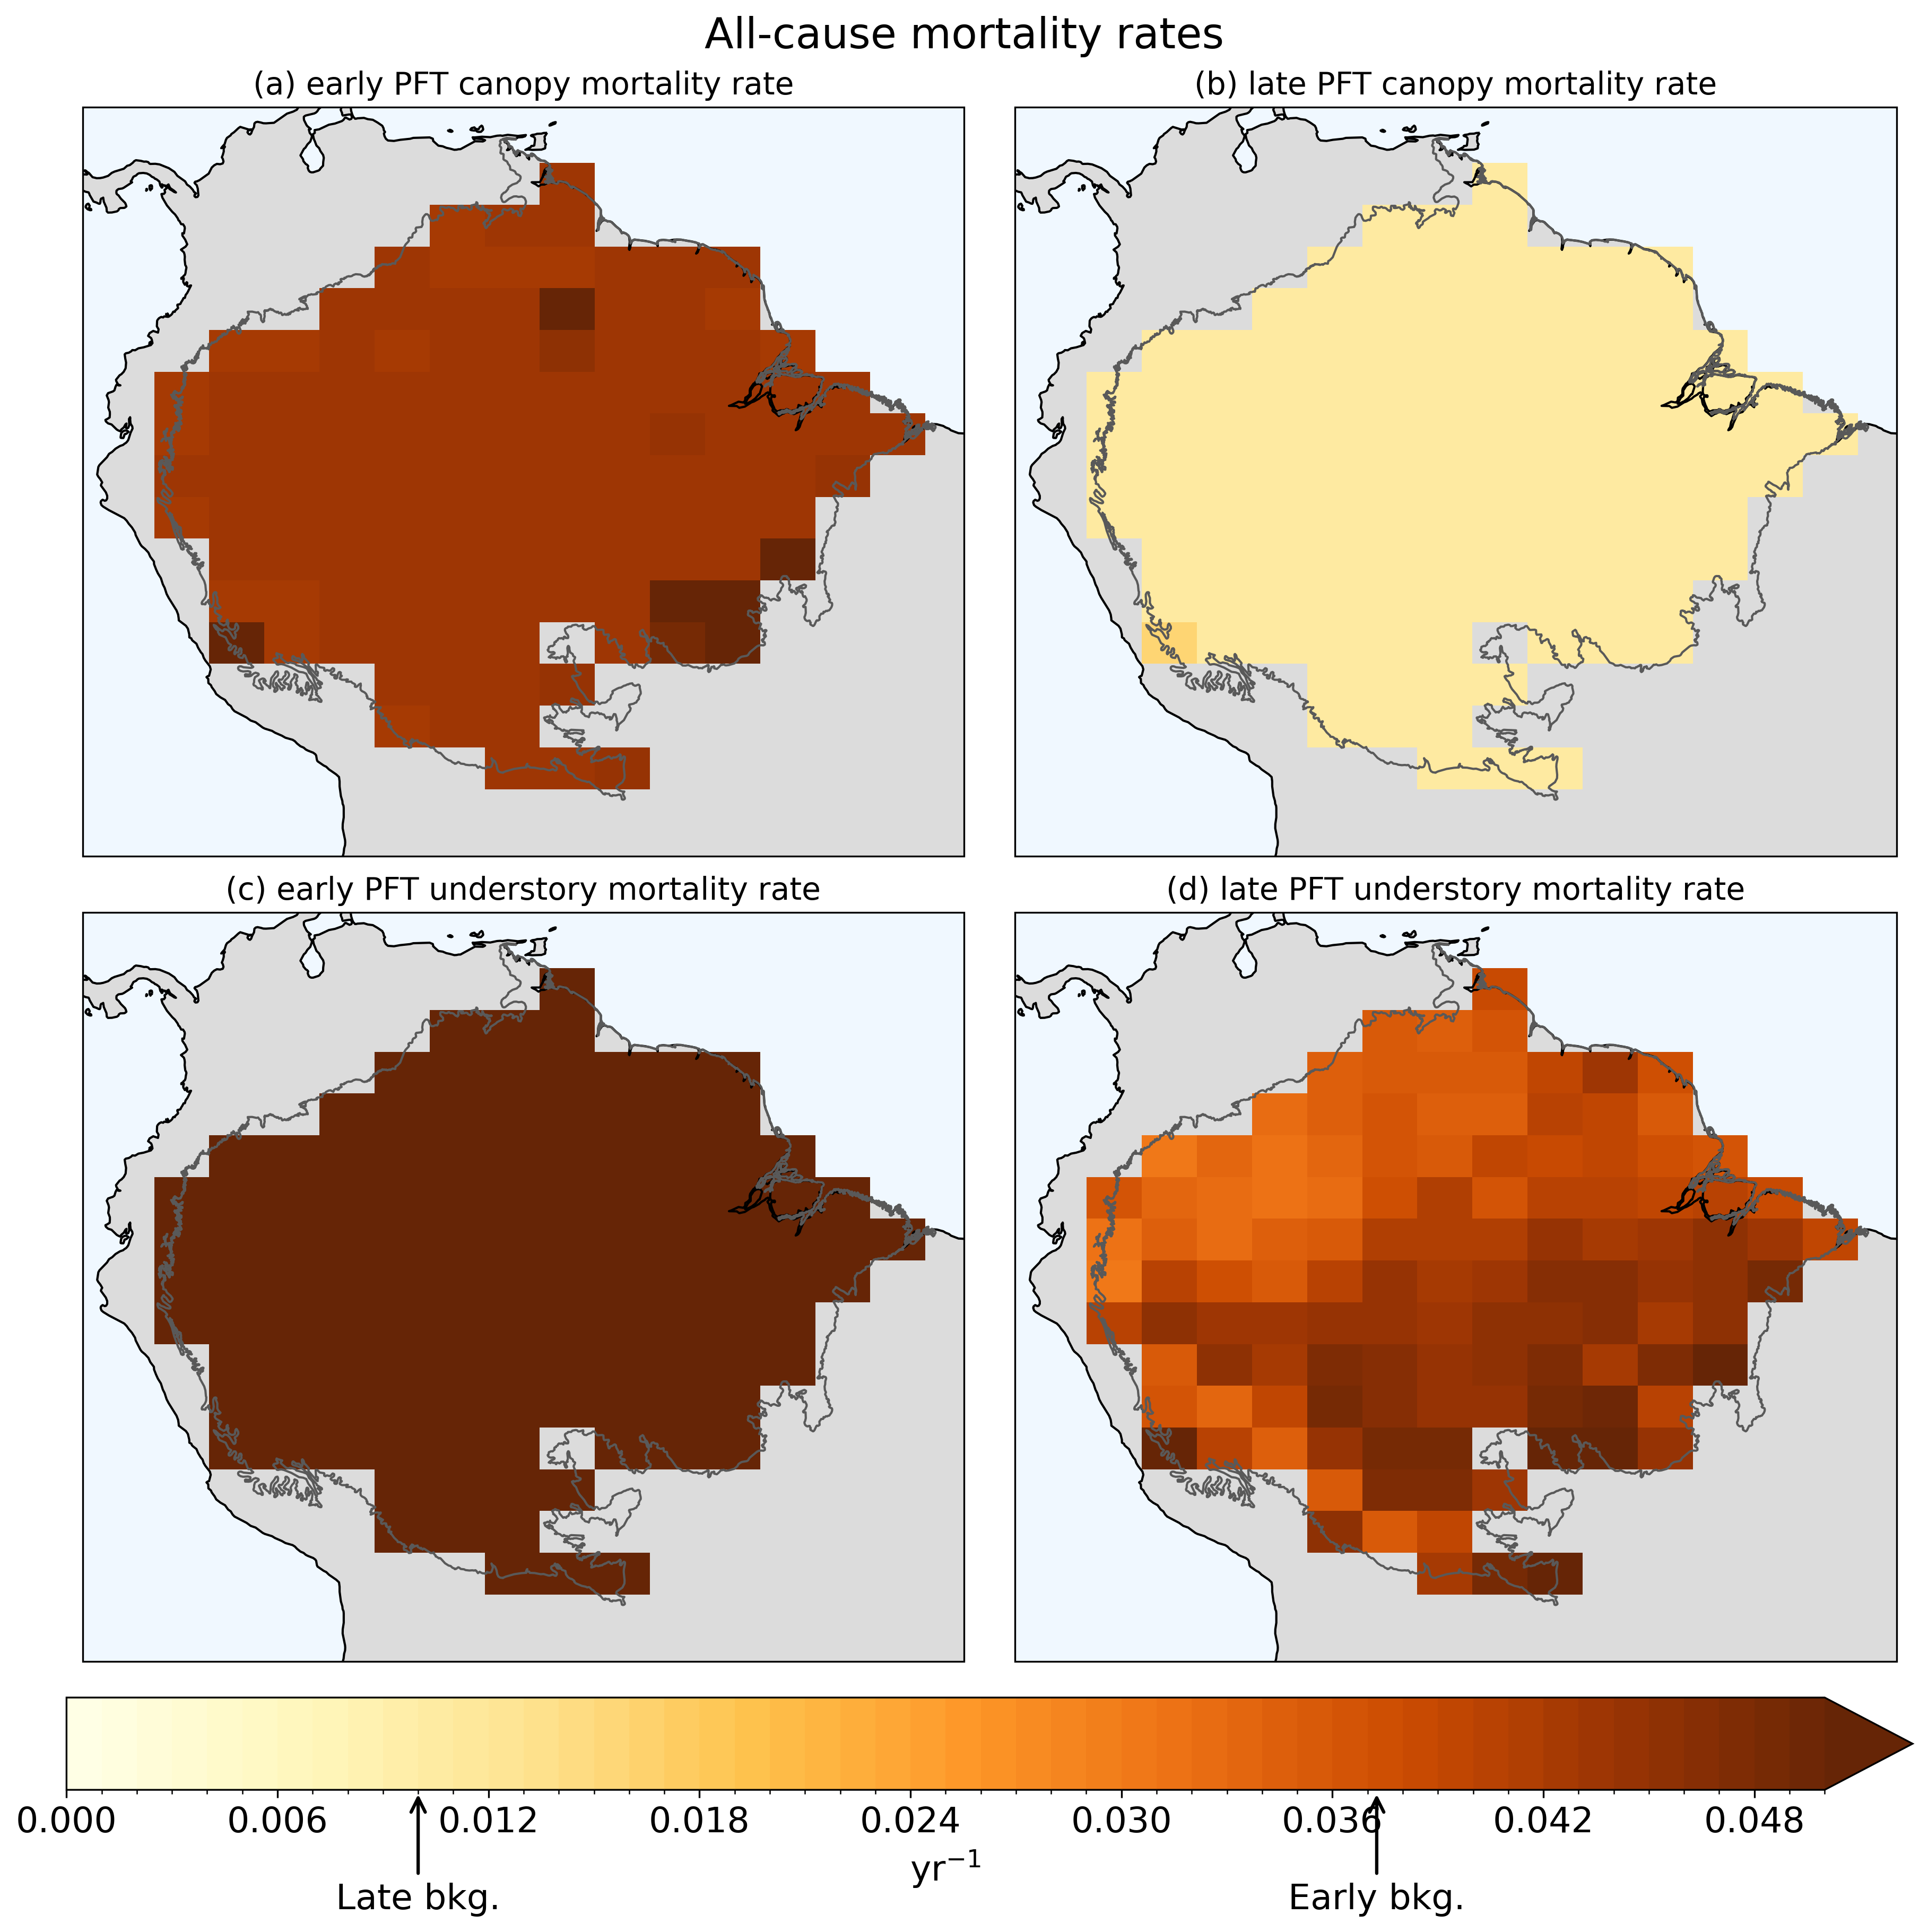

In [58]:
levels = np.linspace(0, 0.05, 51)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 12),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

ax1, ax2, ax3, ax4 = axes.flatten()

# First panel: early PFT canopy
im1 = canopy_mort_norm.where(Mask > 0).isel(fates_levpft=0).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax1,
    add_colorbar=False,  # Turn off individual colorbar
)
ax1.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax1.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax1.set_title("(a) early PFT canopy mortality rate",fontsize=14)
ax1.coastlines()
ax1.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax1.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax1.set_ylim([min_lat_plotting, max_lat_plotting])

# First panel: late PFT canopy
im2 = canopy_mort_norm.where(Mask > 0).isel(fates_levpft=1).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax2,
    add_colorbar=False,  # Turn off individual colorbar
)
ax2.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax2.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax2.set_title("(b) late PFT canopy mortality rate",fontsize=14)
ax2.coastlines()
ax2.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax2.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax2.set_ylim([min_lat_plotting, max_lat_plotting])

# Third panel: early PFT ustory
im3 = ustory_mort_norm.where(Mask > 0).isel(fates_levpft=0).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax3,
    add_colorbar=False,  # Turn off individual colorbar
)
ax3.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax3.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax3.set_title("(c) early PFT understory mortality rate",fontsize=14)
ax3.coastlines()
ax3.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax3.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax3.set_ylim([min_lat_plotting, max_lat_plotting])

# Fourth panel: late PFT ustory
im4 = ustory_mort_norm.where(Mask > 0).isel(fates_levpft=1).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax4,
    add_colorbar=False,  # Turn off individual colorbar
)
ax4.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax4.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax4.set_title("(d) late PFT understory mortality rate",fontsize=14)
ax4.coastlines()
ax4.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax4.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax4.set_ylim([min_lat_plotting, max_lat_plotting])

# Add single shared colorbar spanning all subplots
cbar = fig.colorbar(
    im1,
    ax=axes,
    orientation="horizontal",
    shrink=1,
    pad=0.02,
    label="yr$^{-1}$",
)

plt.suptitle("All-cause mortality rates")

bkg_morts = [0.03726, 0.01]
labels = ["Early bkg.", "Late bkg."]

# Loop through and annotate each point underneath the colorbar
for val, text in zip(bkg_morts, labels):
    cbar.ax.annotate(
        text,
        xy=(val, 0.0),            # Arrow tip points to bottom edge (y=0.0)
        xytext=(val, -1.),       # Text positioned below the colorbar
        ha="center",              # Center text horizontally
        va="top",                 # Align top of text to xytext position
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            lw=1.5,
        ),
        annotation_clip=False,    # Allow drawing outside colorbar bounds
    )

In [59]:
canopy_mort_norm=canopy_cstarv_mort.sum(dim='fates_levscls').mean(dim='time')/nplant_canopy.sum(dim='fates_levscls').mean(dim='time')

In [60]:
ustory_mort_norm=ustory_cstarv_mort.sum(dim='fates_levscls').mean(dim='time')/nplant_ustory.sum(dim='fates_levscls').mean(dim='time')

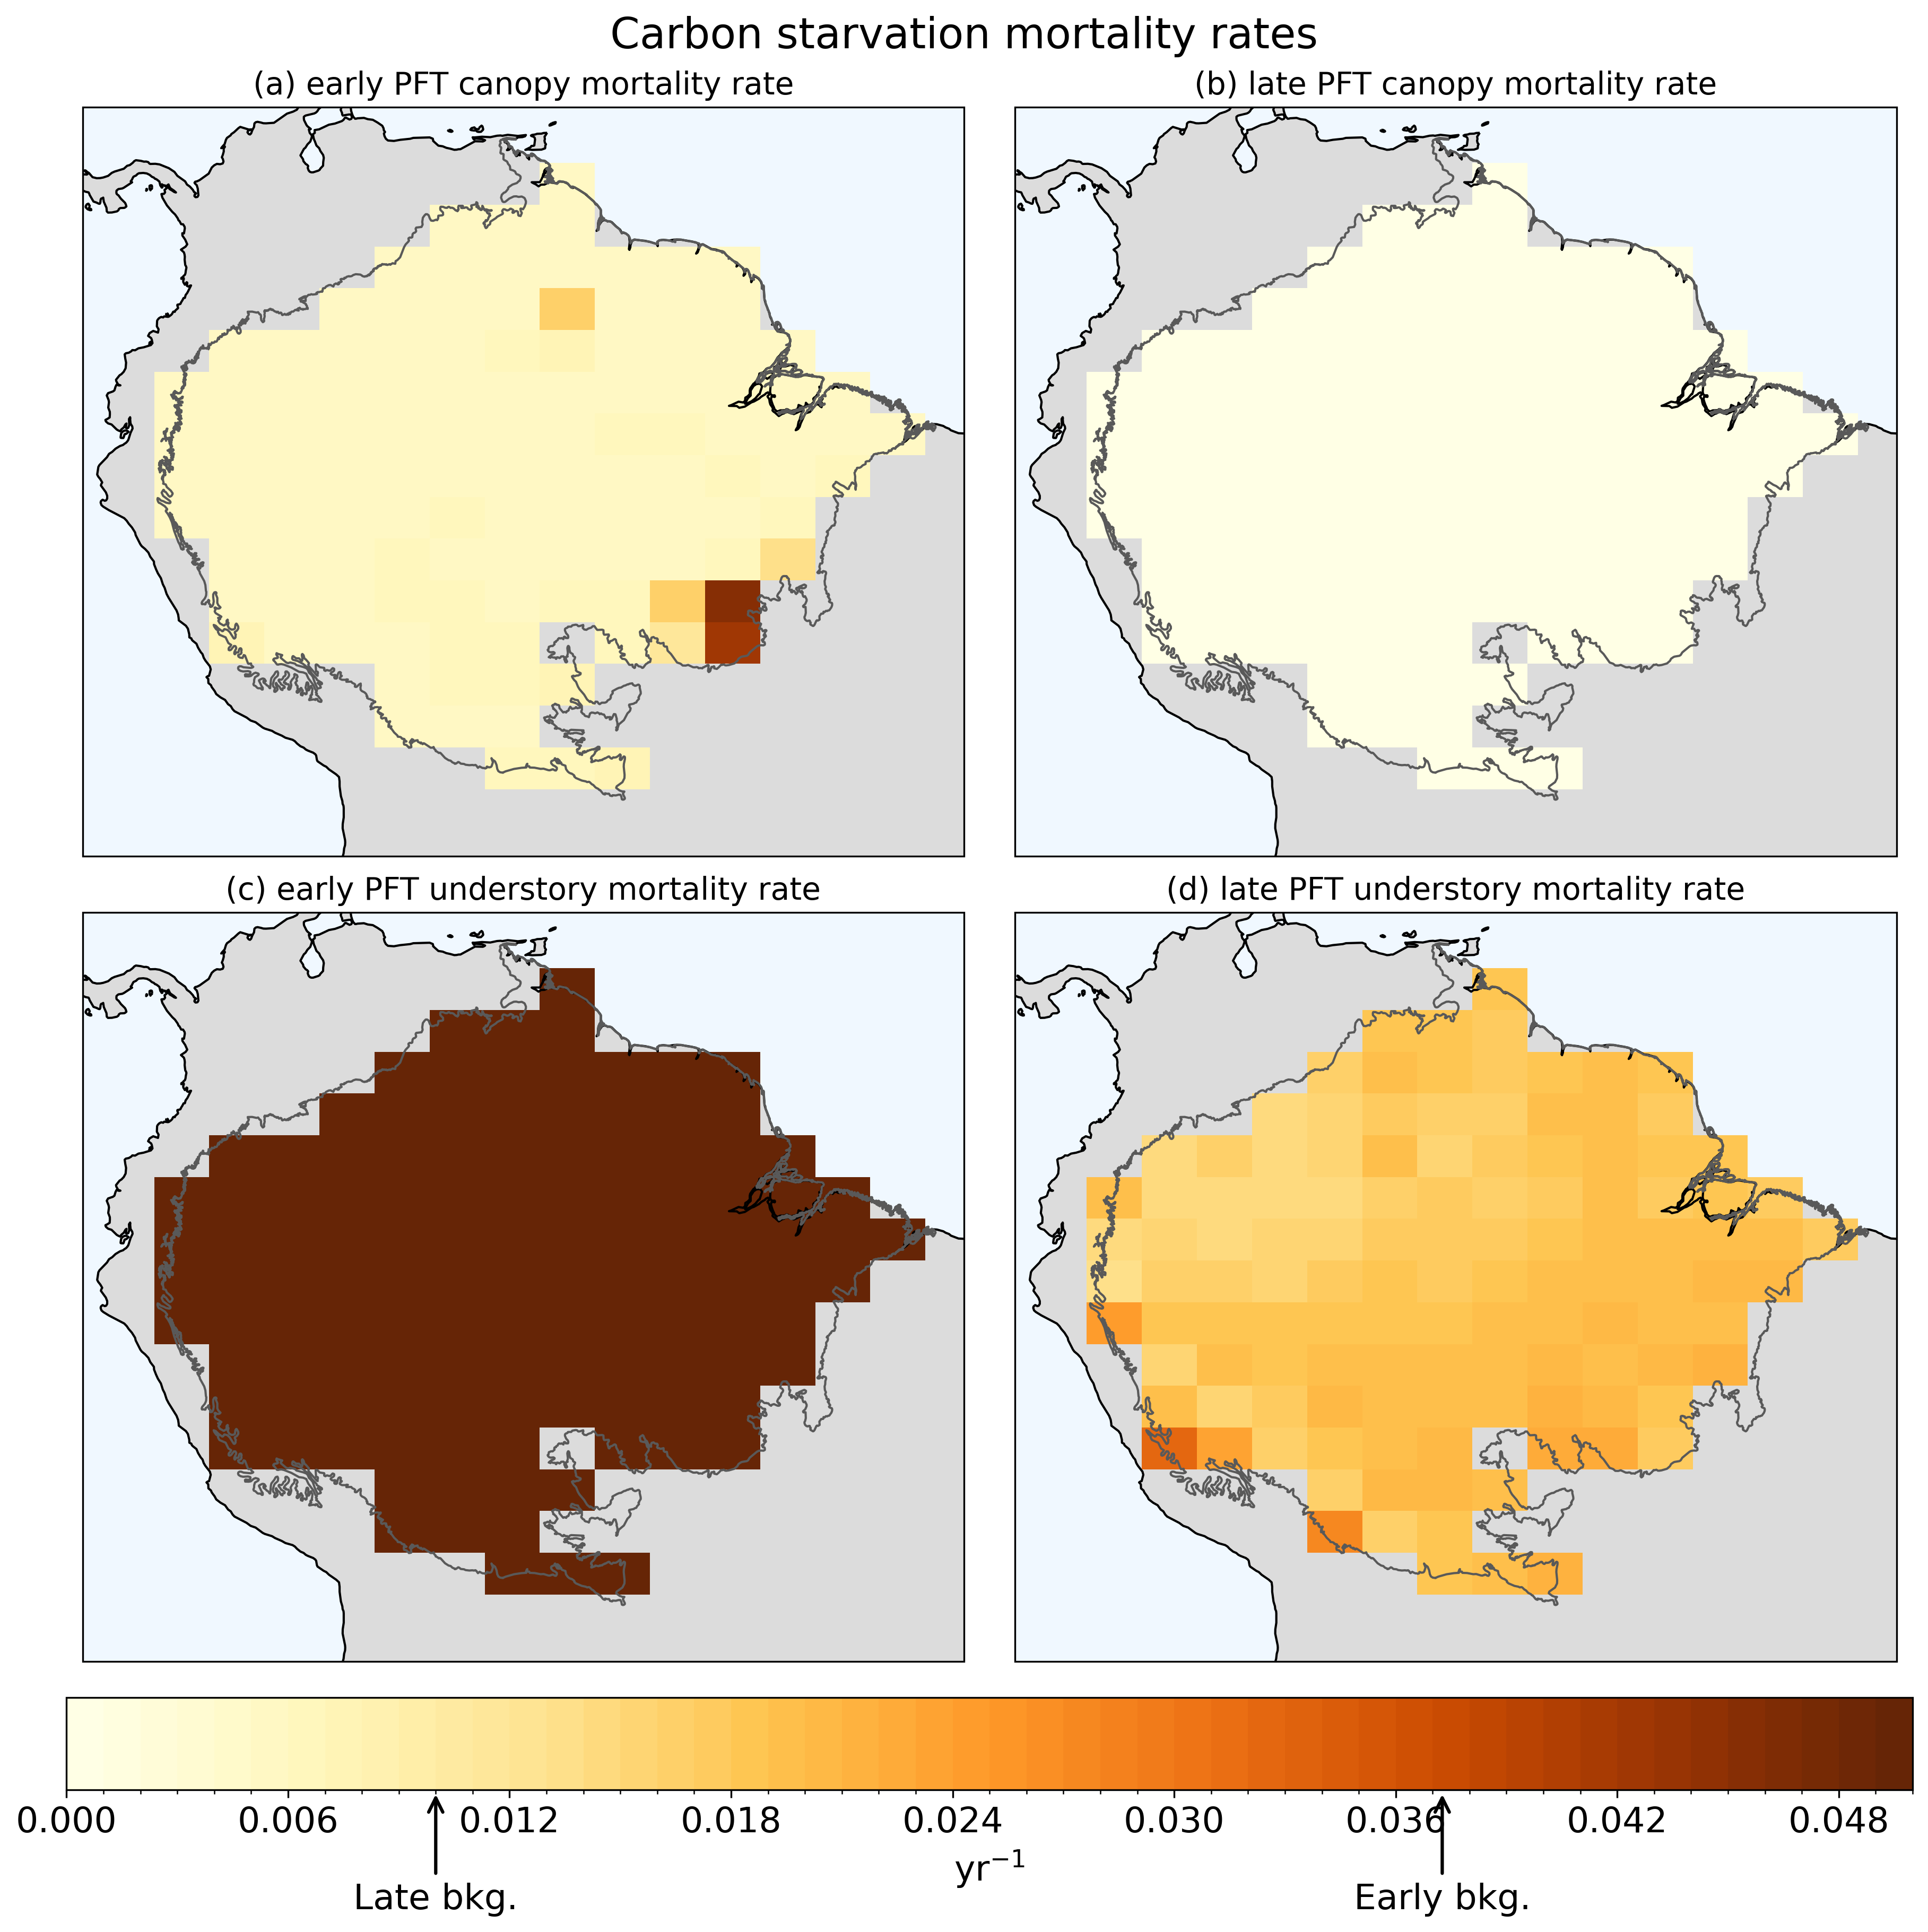

In [61]:
levels = np.linspace(0, 0.05, 51)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 12),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

ax1, ax2, ax3, ax4 = axes.flatten()

# First panel: early PFT canopy
im1 = canopy_mort_norm.where(Mask > 0).isel(fates_levpft=0).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax1,
    add_colorbar=False,  # Turn off individual colorbar
)
ax1.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax1.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax1.set_title("(a) early PFT canopy mortality rate",fontsize=14)
ax1.coastlines()
ax1.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax1.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax1.set_ylim([min_lat_plotting, max_lat_plotting])

# First panel: late PFT canopy
im2 = canopy_mort_norm.where(Mask > 0).isel(fates_levpft=1).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax2,
    add_colorbar=False,  # Turn off individual colorbar
)
ax2.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax2.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax2.set_title("(b) late PFT canopy mortality rate",fontsize=14)
ax2.coastlines()
ax2.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax2.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax2.set_ylim([min_lat_plotting, max_lat_plotting])

# Third panel: early PFT ustory
im3 = ustory_mort_norm.where(Mask > 0).isel(fates_levpft=0).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax3,
    add_colorbar=False,  # Turn off individual colorbar
)
ax3.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax3.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax3.set_title("(c) early PFT understory mortality rate",fontsize=14)
ax3.coastlines()
ax3.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax3.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax3.set_ylim([min_lat_plotting, max_lat_plotting])

# Fourth panel: late PFT ustory
im4 = ustory_mort_norm.where(Mask > 0).isel(fates_levpft=1).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax4,
    add_colorbar=False,  # Turn off individual colorbar
)
ax4.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax4.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax4.set_title("(d) late PFT understory mortality rate",fontsize=14)
ax4.coastlines()
ax4.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax4.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax4.set_ylim([min_lat_plotting, max_lat_plotting])

# Add single shared colorbar spanning all subplots
cbar = fig.colorbar(
    im1,
    ax=axes,
    orientation="horizontal",
    shrink=1,
    pad=0.02,
    label="yr$^{-1}$",
)

plt.suptitle("Carbon starvation mortality rates")

bkg_morts = [0.03726, 0.01]
labels = ["Early bkg.", "Late bkg."]

# Loop through and annotate each point underneath the colorbar
for val, text in zip(bkg_morts, labels):
    cbar.ax.annotate(
        text,
        xy=(val, 0.0),            # Arrow tip points to bottom edge (y=0.0)
        xytext=(val, -1.),       # Text positioned below the colorbar
        ha="center",              # Center text horizontally
        va="top",                 # Align top of text to xytext position
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            lw=1.5,
        ),
        annotation_clip=False,    # Allow drawing outside colorbar bounds
    )

In [10]:
impact_mort_norm=impact_mort.sum(dim='fates_levscls').mean(dim='time')/nplant_ustory.sum(dim='fates_levscls').mean(dim='time')

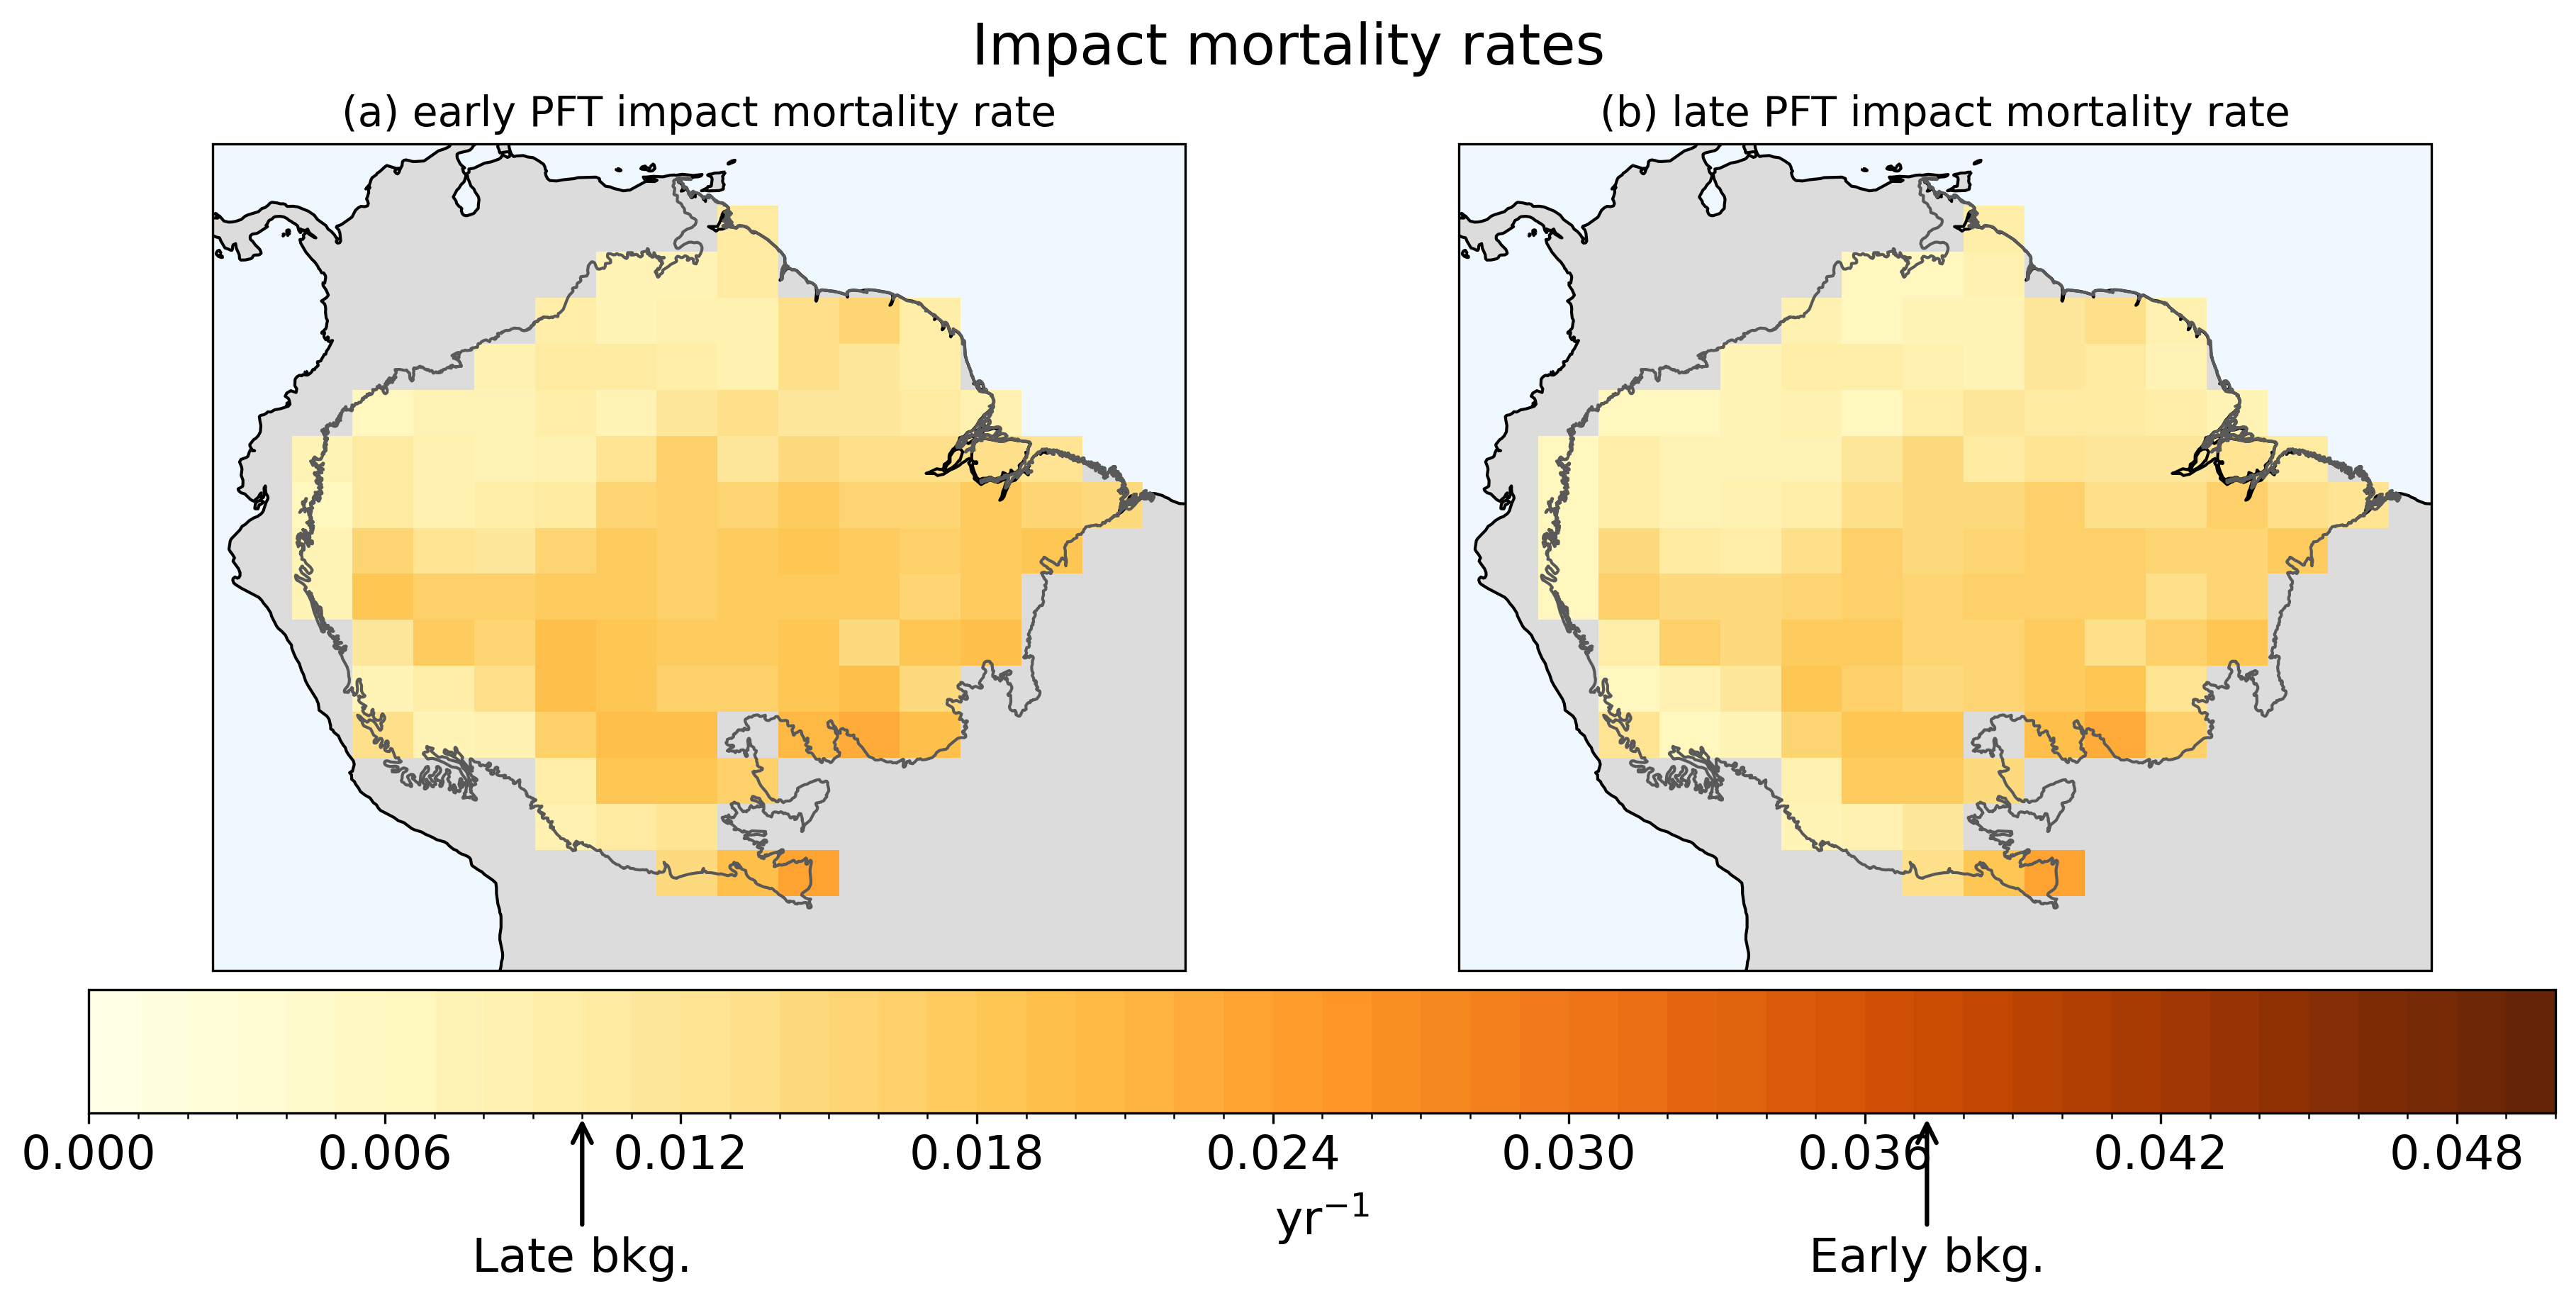

In [11]:
levels = np.linspace(0, 0.05, 51)

# Create figure with 2 subplots
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 6),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)

ax1, ax2 = axes.flatten()

# First panel: early PFT 
im1 = impact_mort_norm.where(Mask > 0).isel(fates_levpft=0).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax1,
    add_colorbar=False,  # Turn off individual colorbar
)
ax1.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax1.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax1.set_title("(a) early PFT impact mortality rate",fontsize=14)
ax1.coastlines()
ax1.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax1.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax1.set_ylim([min_lat_plotting, max_lat_plotting])

# First panel: late PFT 
im2 = impact_mort_norm.where(Mask > 0).isel(fates_levpft=1).plot(
    x="lon",
    y="lat",
    cmap=plt.cm.YlOrBr,
    levels=levels,
    transform=ccrs.PlateCarree(),
    ax=ax2,
    add_colorbar=False,  # Turn off individual colorbar
)
ax2.add_feature(cartopy.feature.LAND, facecolor="gainsboro", zorder=0)
ax2.add_feature(cartopy.feature.OCEAN, facecolor="aliceblue", zorder=0)
ax2.set_title("(b) late PFT impact mortality rate",fontsize=14)
ax2.coastlines()
ax2.add_geometries(
    Reader(Amazon_shapefile).geometries(),
    ccrs.PlateCarree(),
    edgecolor=(0.35, 0.35, 0.35, 1),
    facecolor=(0, 0, 0, 0),
)
ax2.set_xlim([min_lon_plotting - 360.0, max_lon_plotting - 360.0])
ax2.set_ylim([min_lat_plotting, max_lat_plotting])

# Add single shared colorbar spanning all subplots
cbar = fig.colorbar(
    im1,
    ax=axes,
    orientation="horizontal",
    shrink=1,
    pad=0.02,
    label="yr$^{-1}$",
)

plt.suptitle("Impact mortality rates")

bkg_morts = [0.03726, 0.01]
labels = ["Early bkg.", "Late bkg."]

# Loop through and annotate each point underneath the colorbar
for val, text in zip(bkg_morts, labels):
    cbar.ax.annotate(
        text,
        xy=(val, 0.0),            # Arrow tip points to bottom edge (y=0.0)
        xytext=(val, -1.),       # Text positioned below the colorbar
        ha="center",              # Center text horizontally
        va="top",                 # Align top of text to xytext position
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            lw=1.5,
        ),
        annotation_clip=False,    # Allow drawing outside colorbar bounds
    )